In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv('student-mat.csv', sep=';')

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [8]:
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset Shape: (395, 33)
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [9]:
print("Rows and Columns:", df.shape)
print("Total Students:", len(df))
print("Total Features:", len(df.columns))

Rows and Columns: (395, 33)
Total Students: 395
Total Features: 33


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [11]:
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [12]:
df["Average"] = (df["G1"] + df["G2"] + df["G3"]) / 3

df[["G1", "G2", "G3", "Average"]].head(10)

,G1,G2,G3,Average
0,5,6,6,5.666667
1,5,5,6,5.333333
2,7,8,10,8.333333
3,15,14,15,14.666667
4,6,10,10,8.666667
5,15,15,15,15.000000
6,12,12,11,11.666667
7,6,5,6,5.666667
8,16,18,19,17.666667
9,14,15,15,14.666667


In [13]:
print("Highest Average:", df["Average"].max())
print("Lowest Average:", df["Average"].min())
print("Class Average:", df["Average"].mean())

Highest Average: 19.333333333333332
Lowest Average: 1.3333333333333333
Class Average: 10.67932489451477


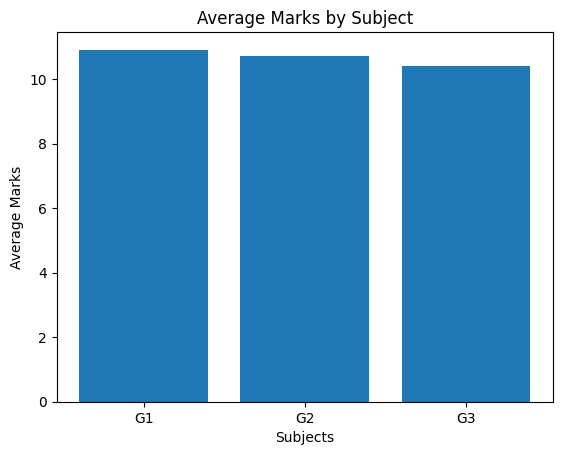

In [14]:
subjects = ["G1", "G2", "G3"]

averages = [
    df["G1"].mean(),
    df["G2"].mean(),
    df["G3"].mean()
]

plt.bar(subjects, averages)
plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.show()

In [15]:
df["Result"] = np.where(df["G3"] >= 10, "Pass", "Fail")

result_count = df["Result"].value_counts()

print(result_count)

Result
Pass    265
Fail    130
Name: count, dtype: int64


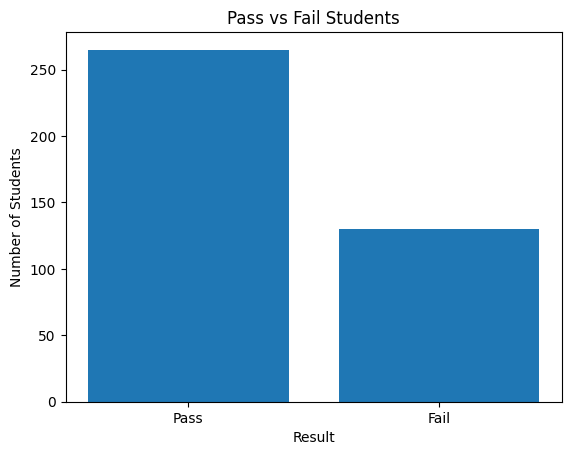

In [16]:
plt.bar(result_count.index, result_count.values)

plt.title("Pass vs Fail Students")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.show()

In [17]:
top_students = df.sort_values(
    by="G3", ascending=False
).head(10)

top_students[["school", "sex", "age", "G1", "G2", "G3", "Average"]]

,school,sex,age,G1,G2,G3,Average
47,GP,M,16,19,19,20,19.333333
286,GP,F,18,18,18,19,18.333333
374,MS,F,18,19,18,19,18.666667
110,GP,M,15,18,19,19,18.666667
8,GP,M,15,16,18,19,17.666667
113,GP,M,15,18,19,19,18.666667
91,GP,F,15,16,17,18,17.000000
42,GP,M,15,19,18,18,18.333333
36,GP,M,15,15,16,18,16.333333
104,GP,M,15,16,18,18,17.333333


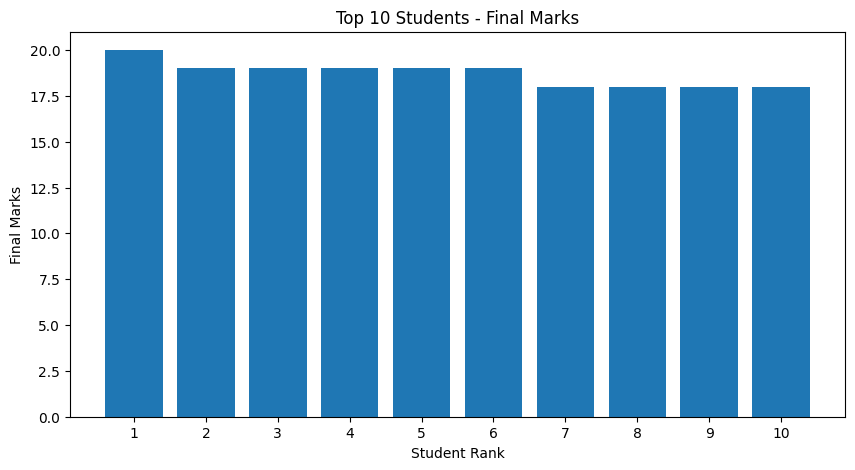

In [18]:
plt.figure(figsize=(10, 5))

plt.bar(range(1, 11), top_students["G3"])

plt.title("Top 10 Students - Final Marks")
plt.xlabel("Student Rank")
plt.ylabel("Final Marks")

plt.xticks(range(1, 11))
plt.show()

In [19]:
print("STUDENT PERFORMANCE ANALYSIS")
print("--------------------------------")

print("Total Students:", len(df))
print("Class Average:", round(df["Average"].mean(), 2))
print("Highest Average:", round(df["Average"].max(), 2))
print("Lowest Average:", round(df["Average"].min(), 2))

print("\nPass Students:", (df["Result"] == "Pass").sum())
print("Fail Students:", (df["Result"] == "Fail").sum())

print("\nProject Completed Successfully!")

STUDENT PERFORMANCE ANALYSIS
--------------------------------
Total Students: 395
Class Average: 10.68
Highest Average: 19.33
Lowest Average: 1.33

Pass Students: 265
Fail Students: 130

Project Completed Successfully!


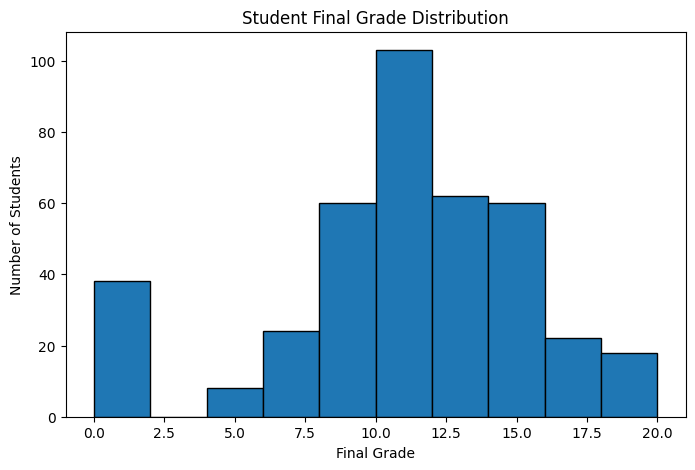

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["G3"], bins=10, edgecolor="black")

plt.title("Student Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

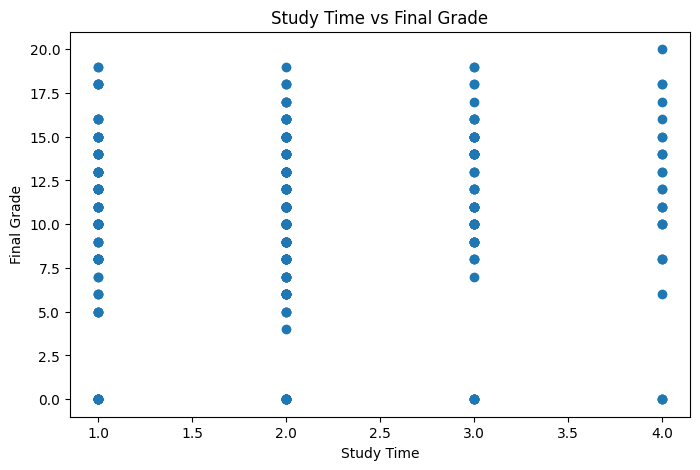

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(df["studytime"], df["G3"])

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Final Grade")

plt.show()

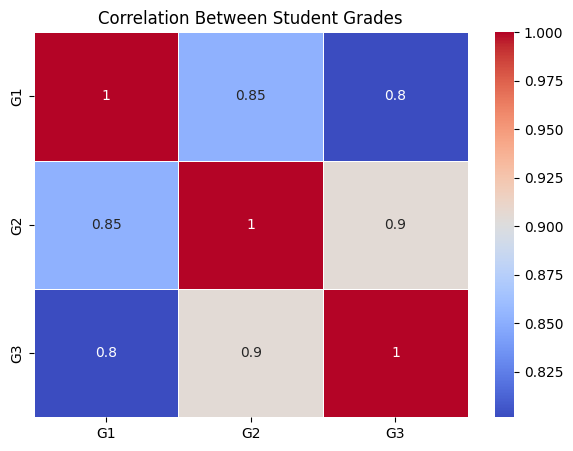

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

grades = df[["G1", "G2", "G3"]]

correlation = grades.corr()

plt.figure(figsize=(7,5))

sns.heatmap(correlation, annot=True, cmap="coolwarm",
            linewidths=0.5)

plt.title("Correlation Between Student Grades")

plt.show()

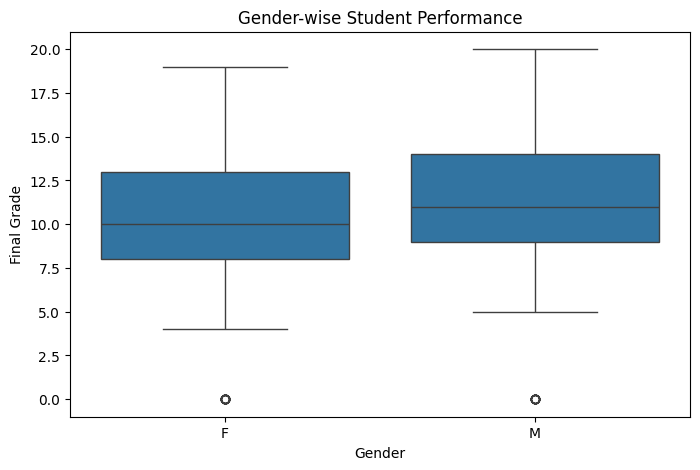

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.boxplot(x="sex", y="G3", data=df)

plt.title("Gender-wise Student Performance")
plt.xlabel("Gender")
plt.ylabel("Final Grade")

plt.show()

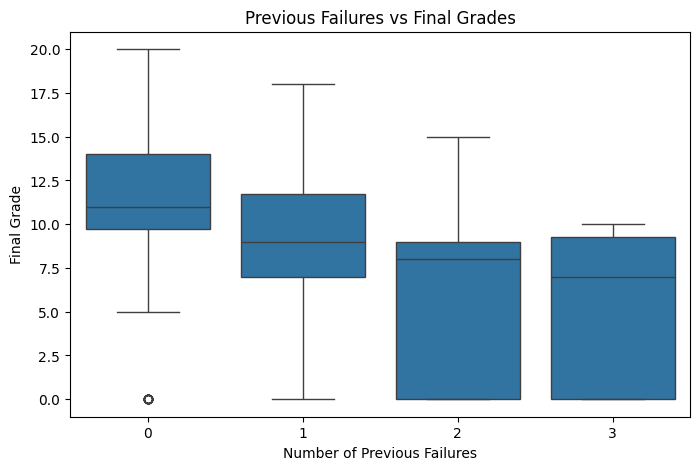

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.boxplot(x="failures", y="G3", data=df)

plt.title("Previous Failures vs Final Grades")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade")

plt.show()

In [25]:
# 1. Overall student performance
print("Average Final Grade:", df["G3"].mean())

# 2. Highest final grade
print("Highest Final Grade:", df["G3"].max())

# 3. Lowest final grade
print("Lowest Final Grade:", df["G3"].min())

# 4. Average grade by gender
print("\nAverage Grade by Gender:")
print(df.groupby("sex")["G3"].mean())

# 5. Average grade by study time
print("\nAverage Grade by Study Time:")
print(df.groupby("studytime")["G3"].mean())

# 6. Average grade by previous failures
print("\nAverage Grade by Failures:")
print(df.groupby("failures")["G3"].mean())

Average Final Grade: 10.415189873417722
Highest Final Grade: 20
Lowest Final Grade: 0

Average Grade by Gender:
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64

Average Grade by Study Time:
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

Average Grade by Failures:
failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64
